# RQ1 - Nelson-Siegel: uoc luong cau truc ky han

Muc tieu: trich Level/Slope/Curvature tu 10 ky han (3M-30Y, bo DGS1MO), λ co dinh = 0,0609×12 = 0,7308 (ky han tinh bang NAM), OLS theo ngay, khong forward-fill; doi chieu OLS vs NLS.

In [1]:
import sys
sys.path.append('..')
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src import config, data_fetch, utils, interactive as ia
pd.options.display.float_format = '{:.4f}'.format
from src import nelson_siegel as ns

## 1. Du lieu (cache; `python scripts/run_pipeline.py --refresh` de tai lai tu FRED)

In [2]:
yields, macro, recession = data_fetch.fetch_fred_data(use_cache=True)
codes = list(config.NS_SERIES)
maturities = list(config.NS_SERIES.values())
print(yields.shape, yields.index.min().date(), '->', yields.index.max().date())
yields[codes].tail()

(6687, 11) 2000-01-03 -> 2026-09-25


,DGS3MO,DGS6MO,DGS1,DGS2,DGS3,DGS5,DGS7,DGS10,DGS20,DGS30
date,,,,,,,,,,
2026-09-21,4.1700,4.2700,4.4500,4.7600,4.8200,4.8300,4.8900,4.9600,5.3300,5.2900
2026-09-22,4.1600,4.2600,4.4300,4.7100,4.8100,4.8300,4.8900,4.9600,5.3300,5.2900
2026-09-23,4.1900,4.3100,4.4900,4.8500,4.9700,4.9900,5.0500,5.1100,5.4500,5.4000
2026-09-24,4.2400,4.3400,4.5100,4.8700,4.9900,5.0300,5.1000,5.1800,5.5300,5.4700
2026-09-25,4.2400,4.3300,4.5000,4.8100,4.9400,4.9800,5.0600,5.1700,5.5400,5.4900


## 2. Uoc luong NS (OLS, λ co dinh) theo ngay
Moi ngay can >= 9/10 ky han.

In [3]:
factors_ols = ns.estimate_ns_timeseries(yields[codes], maturities, method='ols')
print('lambda =', config.NS_LAMBDA_FIXED)
factors_ols[['level','slope','curvature','rmse','r2']].describe()

lambda = 0.7308


,level,slope,curvature,rmse,r2
count,6687.0000,6687.0000,6687.0000,6687.0000,6687.0000
mean,4.0999,-1.9521,-2.8592,0.0934,0.9304
std,1.2413,1.8089,2.2572,0.0421,0.1368
min,0.9479,-5.2766,-8.1433,0.0143,0.0072
25%,3.0366,-3.4534,-4.6108,0.0644,0.9340
50%,4.3918,-2.1143,-2.6233,0.0860,0.9786
75%,5.0268,-0.4745,-1.3799,0.1163,0.9948
max,6.8263,2.3142,3.9416,0.2775,0.9999


## 3. Doi chieu OLS vs NLS (mau phan tang: moi 25 ngay tren toan ky 2000-2026)

Hoi tu 100% **khong** co nghia NLS tot hon: NLS fit khit hon (RMSE thap hon) nhung nhan to bat on va mat y nghia kinh te (xem bang tom tat).

In [5]:
comparison, nls_conv_rate = ns.compare_ols_vs_nls(yields[codes], maturities, step=config.NLS_COMPARE_STEP)
summ = ns.summarize_ols_vs_nls(comparison, long_yield=yields['DGS30'])
print(f'Ngay so sanh: {len(comparison)} | NLS hoi tu: {nls_conv_rate:.1%}')
print(f"RMSE TB (bp): OLS {summ['rmse_ols_bp']:.1f} | NLS {summ['rmse_nls_bp']:.1f}")
print(f"lambda NLS: trung vi {summ['lam_nls_median']:.2f} (p10 {summ['lam_nls_p10']:.2f}, p90 {summ['lam_nls_p90']:.2f}) - OLS co dinh 0.73")
for k in ('level','slope','curvature'):
    print(f"{k:9s} tuong quan OLS~NLS {summ[k+'_corr_ols_nls']:.2f} | doi dau {summ[k+'_sign_flip_share']:.0%} | do lech chuan OLS {summ[k+'_sd_ols']:.2f} vs NLS {summ[k+'_sd_nls']:.2f}")
print(f"Tuong quan level voi lai suat 30Y: OLS {summ['level_corr_long_yield_ols']:.2f} | NLS {summ['level_corr_long_yield_nls']:.2f}")
comparison.head()

Ngay so sanh: 268 | NLS hoi tu: 100.0%
RMSE TB (bp): OLS 9.3 | NLS 5.1
lambda NLS: trung vi 0.45 (p10 0.16, p90 0.87) - OLS co dinh 0.73
level     tuong quan OLS~NLS 0.37 | doi dau 4% | do lech chuan OLS 1.25 vs NLS 2.65
slope     tuong quan OLS~NLS 0.55 | doi dau 7% | do lech chuan OLS 1.82 vs NLS 2.99
curvature tuong quan OLS~NLS 0.31 | doi dau 21% | do lech chuan OLS 2.24 vs NLS 5.46
Tuong quan level voi lai suat 30Y: OLS 0.99 | NLS 0.38


,level_ols,slope_ols,curvature_ols,lam_ols,rmse_ols,r2_ols,converged_ols,n_maturities_ols,level_nls,slope_nls,curvature_nls,lam_nls,rmse_nls,r2_nls,converged_nls,n_maturities_nls
date,,,,,,,,,,,,,,,,
2000-01-03,6.7266,-1.3290,0.9586,0.7308,0.1083,0.9312,True,10,6.7330,-1.5608,0.0518,2.0000,0.0954,0.9466,True,10
2000-02-08,6.2765,-0.8955,2.9436,0.7308,0.0729,0.9551,True,10,6.1919,-0.7125,3.0703,0.5877,0.0651,0.9642,True,10
2000-03-15,6.1390,-0.4614,2.0091,0.7308,0.0807,0.8620,True,10,6.0948,-0.3628,2.0478,0.6144,0.0788,0.8686,True,10
2000-04-19,5.8994,-0.2215,1.7189,0.7308,0.0865,0.7533,True,10,5.8991,-0.2208,1.7189,0.7298,0.0865,0.7533,True,10
2000-05-25,6.1762,-0.4613,2.4962,0.7308,0.1241,0.7808,True,10,6.1533,-0.4066,2.5040,0.6763,0.1237,0.7821,True,10


## 4. Fit tai 3 thoi diem dac trung (normal / flat / inverted theo β1)

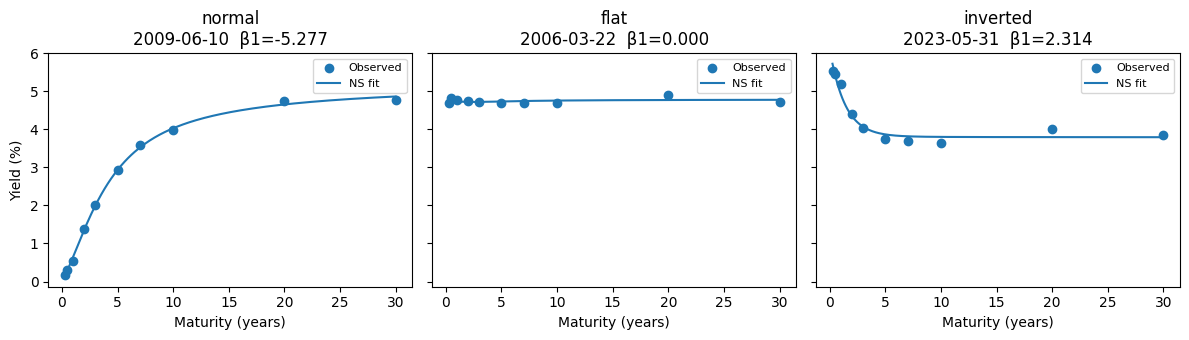

In [6]:
slope = factors_ols['slope']
dates = {'normal': slope.idxmin(), 'flat': slope.abs().idxmin(), 'inverted': slope.idxmax()}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
tau = np.asarray(maturities, dtype=float)
for ax, (label, dt) in zip(axes, dates.items()):
    b0, b1, b2, lam = factors_ols.loc[dt, ['level', 'slope', 'curvature', 'lam']]
    grid = np.linspace(0.25, 30, 200)
    ax.scatter(tau, yields.loc[dt, codes].values, label='Observed', zorder=3)
    ax.plot(grid, ns.nelson_siegel(grid, b0, b1, b2, lam), label='NS fit')
    ax.set_title(f"{label}\n{pd.Timestamp(dt).date()}  β1={b1:.3f}"); ax.set_xlabel('Maturity (years)'); ax.legend(fontsize=8)
axes[0].set_ylabel('Yield (%)'); fig.tight_layout(); plt.show()

## 5. Xuat file ban giao (cung logic voi pipeline)
Nhan to THANG = quan sat hop le cuoi thang; bo thang chua ket thuc. 5 cot: level, slope, curvature, rmse, n_maturities.

In [7]:
from pathlib import Path
Path('../data').mkdir(exist_ok=True); Path('../outputs').mkdir(exist_ok=True)
factors_monthly = utils.ensure_monthly_freq(ns.monthly_factors(factors_ols))
factors_monthly.to_csv('../data/ns_factors_monthly.csv')
factors_ols.to_csv('../data/ns_factors_daily.csv')
factors_ols[['rmse','r2']].describe().to_csv('../outputs/rq1_fit_summary.csv')
print(factors_monthly.shape, factors_monthly.index[-1])
factors_monthly.tail()

(320, 5) 2026-08


,level,slope,curvature,rmse,n_maturities
date,,,,,
2026-04,5.0446,-1.1893,-2.3826,0.1214,10
2026-05,5.0296,-1.1996,-1.8929,0.1185,10
2026-06,4.9318,-0.8967,-1.5813,0.1190,10
2026-07,5.3054,-1.3540,-1.5406,0.1217,10
2026-08,5.2633,-1.2766,-1.3058,0.1150,10


## 6. Bieu do 3D tuong tac (keo de xoay, cuon de zoom, hover de doc gia tri)

In [8]:
ia.fig_yield_surface(yields).show()

In [8]:
ia.fig_ns_surface(factors_monthly).show()

In [9]:
rec = pd.read_csv('../data/recession.csv', index_col=0, parse_dates=True).iloc[:, 0]
ia.fig_factor_path_3d(factors_monthly, rec).show()

In [10]:
ia.fig_factors_2d(factors_monthly, rec).show()